# 03 · Modelos — Árbol de decisión, Random Forest e híbrido K-Means + RF

- **Objetivo:** `riesgo_academico` (1 = nota_final < 3.0).
- **Features:** las de `features.FEATURES`. Nunca se usan `nota_final`, `riesgo_academico` ni `id_estudiante`.
- **Partición:** train/test por estudiante (notebook 01). Los hiperparámetros se ajustan con **GroupKFold (5)** por `id_estudiante`, solo dentro de train.
- **Desbalance:** se usa `class_weight="balanced"`. La métrica para elegir hiperparámetros es la **PR-AUC** (average precision) de la clase riesgo.
- **Pipeline:** la imputación, el one-hot y el K-Means se ajustan dentro de cada fold.

Los datos son **sintéticos**, así que las métricas validan el pipeline y no sirven como estimación de precisión real.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_validate
from sklearn.tree import export_text, plot_tree

from features import RAIZ, FEATURES, NUM, CAT, HABITOS, OBJETIVO, GRUPO, PROHIBIDAS, SEED
from modelo import construir, pipeline_kmeans, nombres_clusters

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
df = pd.read_csv(RAIZ / "data/processed/registros_limpios.csv")
train, test = df[df.particion == "train"], df[df.particion == "test"]
Xtr, ytr, gtr = train[FEATURES], train[OBJETIVO], train[GRUPO]
Xte, yte = test[FEATURES], test[OBJETIVO]
assert not PROHIBIDAS & set(Xtr.columns)
assert not set(train[GRUPO]) & set(test[GRUPO])
print("train", Xtr.shape, f"riesgo {ytr.mean():.2%}", "| test", Xte.shape, f"riesgo {yte.mean():.2%}")

train (4804, 19) riesgo 20.98% | test (1196, 19) riesgo 20.90%


## 1. Ajuste de hiperparámetros con GroupKFold

In [2]:
cv = GroupKFold(n_splits=5)
METRICAS = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1",
            "recall": "recall", "precision": "precision"}
grids = {
    "arbol": {"clf__max_depth": [2, 3, 4], "clf__min_samples_leaf": [1, 20, 50],
              "clf__criterion": ["gini", "entropy"]},
    "rf": {"clf__max_depth": [None, 10], "clf__min_samples_leaf": [1, 5, 20],
           "clf__max_features": ["sqrt", 0.5]},
}
grids["hibrido"] = grids["rf"]

busq = {}
for nombre, grid in grids.items():
    gs = GridSearchCV(construir(nombre), grid, scoring=METRICAS, refit="pr_auc", cv=cv, n_jobs=1)
    gs.fit(Xtr, ytr, groups=gtr)
    busq[nombre] = gs
    print(f"{nombre:8s} mejor PR-AUC CV = {gs.best_score_:.4f} | {gs.best_params_}")

arbol    mejor PR-AUC CV = 0.6232 | {'clf__criterion': 'gini', 'clf__max_depth': 4, 'clf__min_samples_leaf': 50}


rf       mejor PR-AUC CV = 0.7132 | {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 20}


hibrido  mejor PR-AUC CV = 0.7136 | {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 20}


In [3]:
filas = []
for nombre, gs in busq.items():
    r, i = gs.cv_results_, gs.best_index_
    filas.append({"modelo": nombre, **{f"cv_{m}": f"{r[f'mean_test_{m}'][i]:.3f} ± {r[f'std_test_{m}'][i]:.3f}"
                                         for m in METRICAS}})
cv_tabla = pd.DataFrame(filas).set_index("modelo")
cv_tabla

,cv_pr_auc,cv_roc_auc,cv_f1,cv_recall,cv_precision
modelo,,,,,
arbol,0.623 ± 0.051,0.866 ± 0.012,0.617 ± 0.037,0.758 ± 0.036,0.522 ± 0.049
rf,0.713 ± 0.050,0.892 ± 0.008,0.642 ± 0.031,0.811 ± 0.015,0.533 ± 0.043
hibrido,0.714 ± 0.048,0.893 ± 0.008,0.644 ± 0.027,0.814 ± 0.012,0.534 ± 0.040


## 2. Evaluación en test (60 estudiantes no vistos)

In [4]:
def metricas(y, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision_riesgo": precision_score(y, pred),
            "recall_riesgo": recall_score(y, pred), "f1_riesgo": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p)}

modelos = {n: gs.best_estimator_ for n, gs in busq.items()}
probas = {n: m.predict_proba(Xte)[:, 1] for n, m in modelos.items()}
test_tabla = pd.DataFrame({n: metricas(yte, p) for n, p in probas.items()}).T
print("PR-AUC de un clasificador al azar (= prevalencia en test):", round(yte.mean(), 3))
test_tabla.round(3)

PR-AUC de un clasificador al azar (= prevalencia en test): 0.209


,accuracy,precision_riesgo,recall_riesgo,f1_riesgo,roc_auc,pr_auc
arbol,0.801,0.518,0.704,0.597,0.854,0.594
rf,0.809,0.527,0.812,0.639,0.885,0.675
hibrido,0.807,0.524,0.820,0.640,0.884,0.675


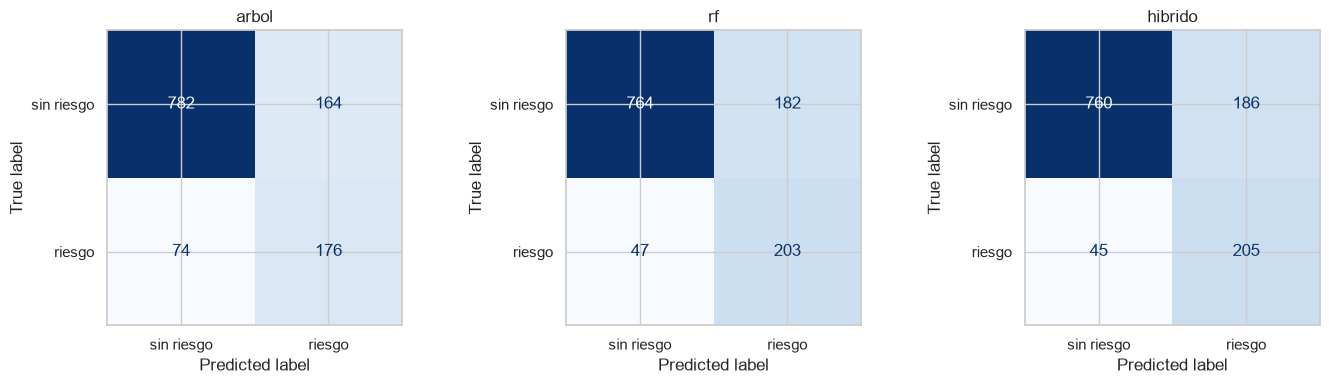

== arbol ==
               precision    recall  f1-score   support

  sin riesgo      0.914     0.827     0.868       946
      riesgo      0.518     0.704     0.597       250

    accuracy                          0.801      1196
   macro avg      0.716     0.765     0.732      1196
weighted avg      0.831     0.801     0.811      1196

== rf ==
               precision    recall  f1-score   support

  sin riesgo      0.942     0.808     0.870       946
      riesgo      0.527     0.812     0.639       250

    accuracy                          0.809      1196
   macro avg      0.735     0.810     0.755      1196
weighted avg      0.855     0.809     0.822      1196

== hibrido ==
               precision    recall  f1-score   support

  sin riesgo      0.944     0.803     0.868       946
      riesgo      0.524     0.820     0.640       250

    accuracy                          0.807      1196
   macro avg      0.734     0.812     0.754      1196
weighted avg      0.856     0.807   

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (n, p) in zip(axs, probas.items()):
    ConfusionMatrixDisplay.from_predictions(yte, (p >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["sin riesgo", "riesgo"], cmap="Blues")
    ax.set_title(n)
plt.tight_layout(); plt.show()
for n, p in probas.items():
    print(f"== {n} ==\n", classification_report(yte, (p >= 0.5).astype(int), digits=3,
                                                target_names=["sin riesgo", "riesgo"]))

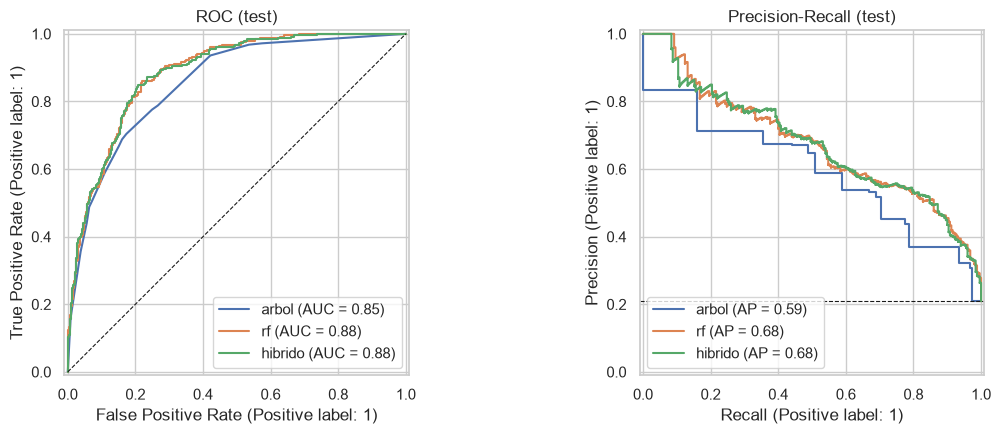

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for n, p in probas.items():
    RocCurveDisplay.from_predictions(yte, p, name=n, ax=axs[0])
    PrecisionRecallDisplay.from_predictions(yte, p, name=n, ax=axs[1])
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8); axs[1].axhline(yte.mean(), color="k", ls="--", lw=0.8)
axs[0].set_title("ROC (test)"); axs[1].set_title("Precision-Recall (test)")
plt.tight_layout(); plt.show()

## 3. Tabla comparativa final

In [7]:
comparativa = cv_tabla.join(test_tabla.round(3).add_prefix("test_"))
comparativa["mejores_hiperparametros"] = [str({k.replace("clf__", ""): v for k, v in busq[n].best_params_.items()})
                                         for n in comparativa.index]
(RAIZ / "reports").mkdir(exist_ok=True)
comparativa.to_csv(RAIZ / "reports/comparativa_modelos.csv")
comparativa

,cv_pr_auc,cv_roc_auc,cv_f1,cv_recall,cv_precision,test_accuracy,test_precision_riesgo,test_recall_riesgo,test_f1_riesgo,test_roc_auc,test_pr_auc,mejores_hiperparametros
modelo,,,,,,,,,,,,
arbol,0.623 ± 0.051,0.866 ± 0.012,0.617 ± 0.037,0.758 ± 0.036,0.522 ± 0.049,0.801,0.518,0.704,0.597,0.854,0.594,"{'criterion': 'gini', 'max_depth': 4, 'min_sam..."
rf,0.713 ± 0.050,0.892 ± 0.008,0.642 ± 0.031,0.811 ± 0.015,0.533 ± 0.043,0.809,0.527,0.812,0.639,0.885,0.675,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."
hibrido,0.714 ± 0.048,0.893 ± 0.008,0.644 ± 0.027,0.814 ± 0.012,0.534 ± 0.040,0.807,0.524,0.820,0.640,0.884,0.675,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."


## 4. Importancia de variables
Se muestran dos medidas:
- **Impureza (MDI)** del Random Forest, calculada sobre las columnas transformadas.
- **Permutación en test:** cuánto baja la PR-AUC al desordenar cada variable original. Es más fiable, porque la MDI favorece a las variables continuas.

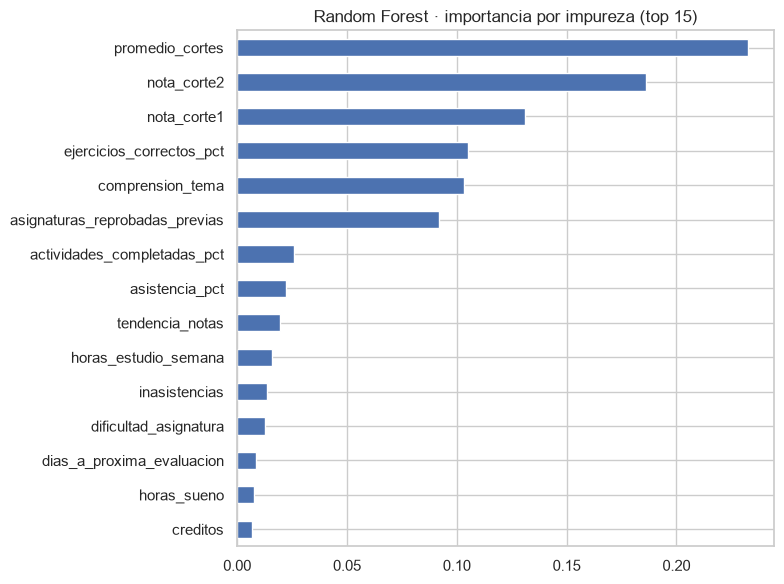

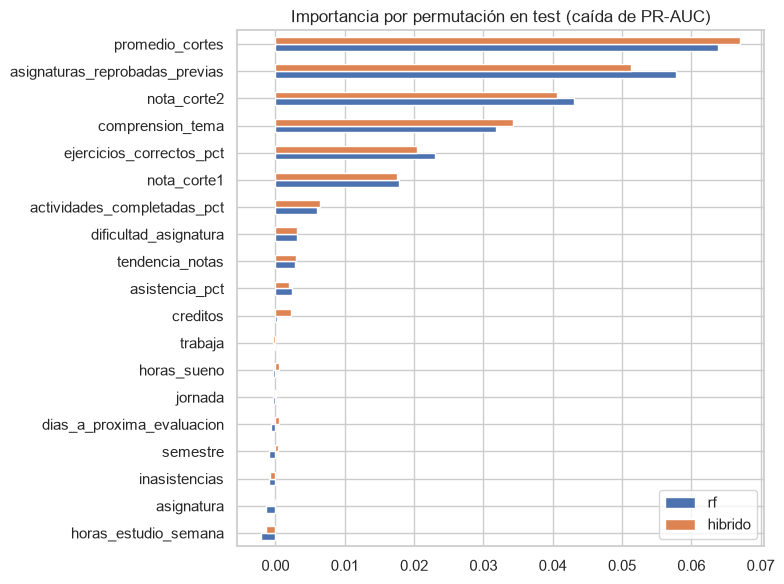

,rf,hibrido
promedio_cortes,0.0639,0.0671
asignaturas_reprobadas_previas,0.0578,0.0513
nota_corte2,0.0430,0.0406
comprension_tema,0.0318,0.0343
ejercicios_correctos_pct,0.0231,0.0204
nota_corte1,0.0178,0.0175
actividades_completadas_pct,0.0060,0.0064
dificultad_asignatura,0.0031,0.0031
tendencia_notas,0.0029,0.0030
asistencia_pct,0.0024,0.0019


In [8]:
rf = modelos["rf"]
mdi = pd.Series(rf["clf"].feature_importances_, index=rf["prep"].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(8, 6)); mdi.tail(15).plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Random Forest · importancia por impureza (top 15)"); plt.tight_layout(); plt.show()

perm = {}
for n in ["rf", "hibrido"]:
    r = permutation_importance(modelos[n], Xte, yte, scoring="average_precision",
                               n_repeats=10, random_state=SEED, n_jobs=1)
    perm[n] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm).sort_values("rf", ascending=False)
fig, ax = plt.subplots(figsize=(8, 6)); perm.iloc[::-1].plot.barh(ax=ax)
ax.set_title("Importancia por permutación en test (caída de PR-AUC)"); plt.tight_layout(); plt.show()
perm.round(4)

In [9]:
hib = modelos["hibrido"]
mdi_h = pd.Series(hib["clf"].feature_importances_, index=hib["prep"].get_feature_names_out())
print("Importancia MDI de las columnas de cluster en el híbrido:")
print(mdi_h[mdi_h.index.str.startswith("cluster")].round(4))

Importancia MDI de las columnas de cluster en el híbrido:
cluster_0    0.0049
cluster_1    0.0198
cluster_2    0.0667
dtype: float64


## 5. Reglas del árbol de decisión (interpretable, profundidad ≤ 4)

In [10]:
arbol = modelos["arbol"]
nombres_cols = list(arbol["prep"].get_feature_names_out())
reglas = export_text(arbol["clf"], feature_names=nombres_cols, show_weights=True, decimals=2)
(RAIZ / "reports/reglas_arbol.txt").write_text(
    "Reglas del árbol de decisión (class_weight=balanced; weights = [sin riesgo, riesgo] ponderados)\n"
    f"Hiperparámetros: {busq['arbol'].best_params_}\n\n" + reglas, encoding="utf-8")
print(reglas)

|--- promedio_cortes <= 3.31
|   |--- promedio_cortes <= 2.91
|   |   |--- asignaturas_reprobadas_previas <= 2.50
|   |   |   |--- promedio_cortes <= 2.62
|   |   |   |   |--- weights: [29.11, 238.29] class: 1
|   |   |   |--- promedio_cortes >  2.62
|   |   |   |   |--- weights: [73.40, 178.72] class: 1
|   |   |--- asignaturas_reprobadas_previas >  2.50
|   |   |   |--- ejercicios_correctos_pct <= 32.00
|   |   |   |   |--- weights: [12.02, 345.53] class: 1
|   |   |   |--- ejercicios_correctos_pct >  32.00
|   |   |   |   |--- weights: [64.54, 569.52] class: 1
|   |--- promedio_cortes >  2.91
|   |   |--- asignaturas_reprobadas_previas <= 3.50
|   |   |   |--- ejercicios_correctos_pct <= 44.20
|   |   |   |   |--- weights: [89.22, 207.32] class: 1
|   |   |   |--- ejercicios_correctos_pct >  44.20
|   |   |   |   |--- weights: [198.06, 181.10] class: 0
|   |   |--- asignaturas_reprobadas_previas >  3.50
|   |   |   |--- ejercicios_correctos_pct <= 48.00
|   |   |   |   |--- weights:

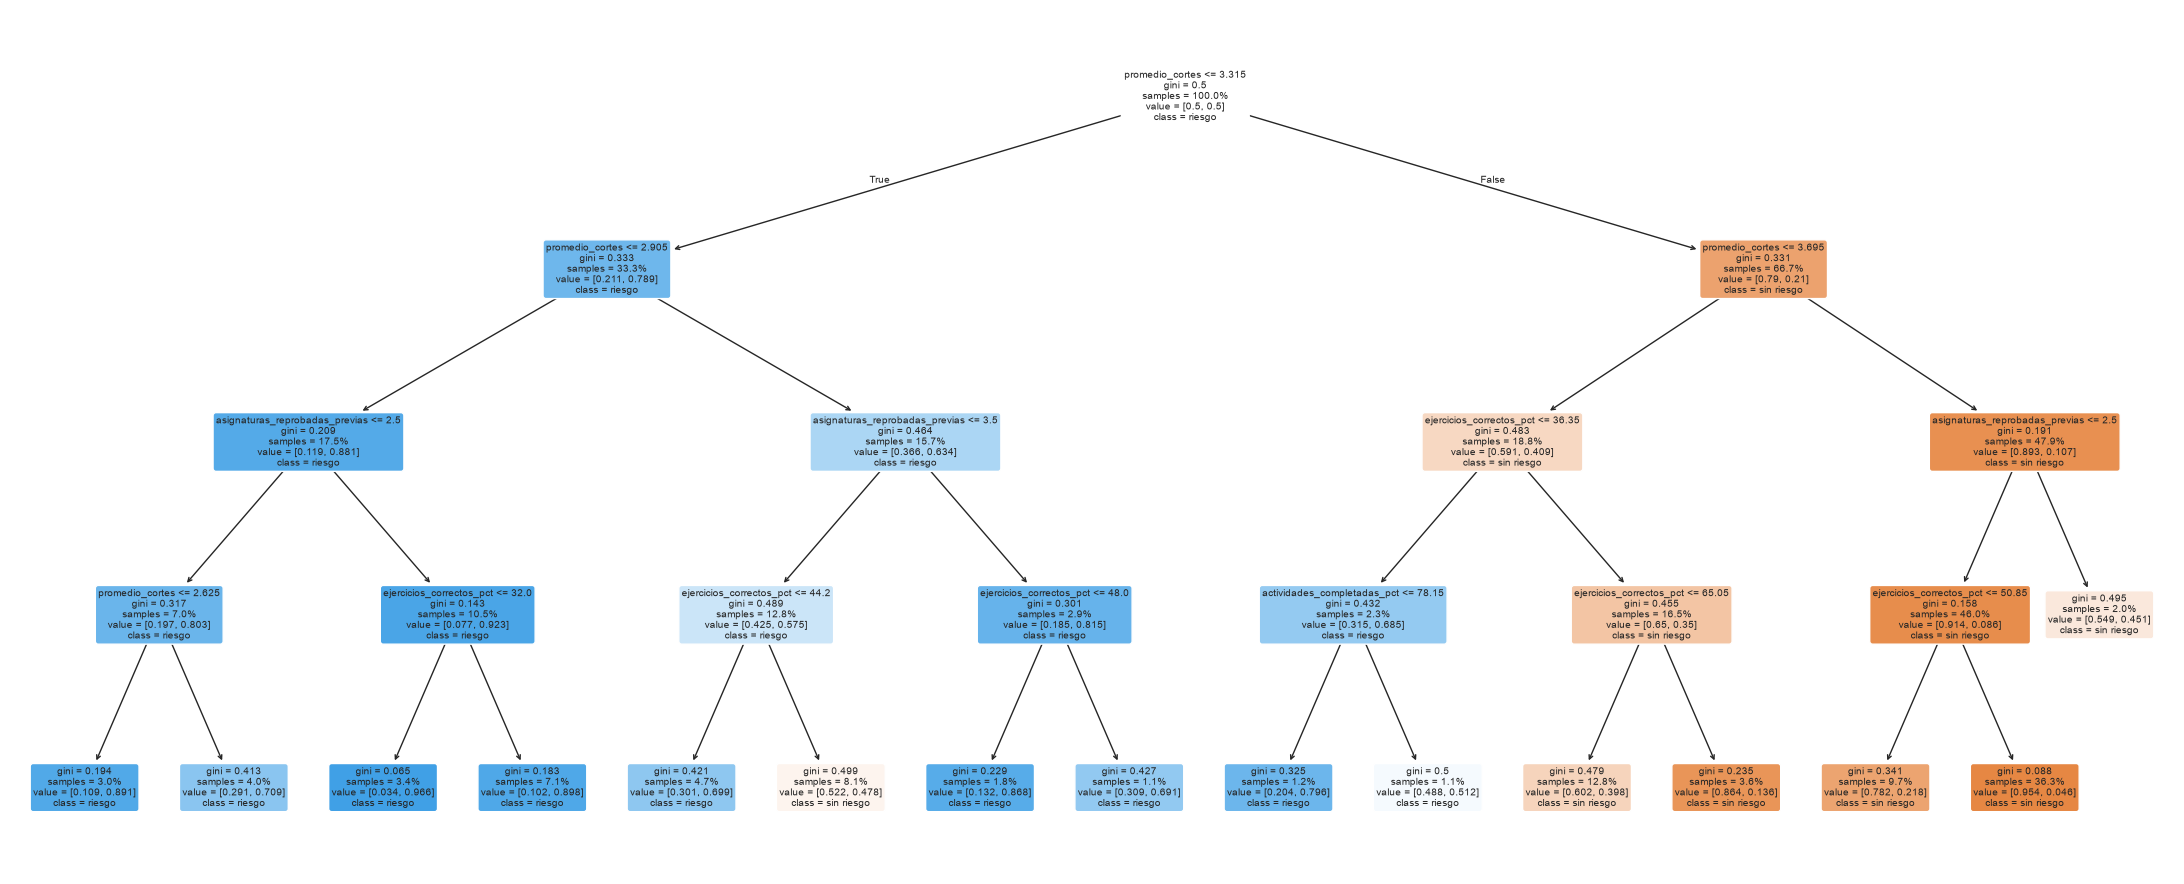

In [11]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol["clf"], feature_names=nombres_cols, class_names=["sin riesgo", "riesgo"],
          filled=True, rounded=True, fontsize=7, proportion=True, ax=ax)
plt.tight_layout(); plt.show()

In [12]:
def hojas_riesgo(tree, cols):
    """Reglas legibles de las hojas que predicen riesgo."""
    t, out = tree.tree_, []
    def texto(cond):  # une cortes repetidos de una misma variable en un intervalo
        partes = []
        for f, (lo, hi) in cond.items():
            if lo > -np.inf and hi < np.inf: partes.append(f"{lo:.2f} < {f} <= {hi:.2f}")
            elif hi < np.inf: partes.append(f"{f} <= {hi:.2f}")
            else: partes.append(f"{f} > {lo:.2f}")
        return " Y ".join(partes) or "(raíz)"
    def rec(nodo, cond):
        if t.children_left[nodo] == -1:
            v = t.value[nodo][0]; n = t.n_node_samples[nodo]
            if v.argmax() == 1:
                out.append((texto(cond), n, v[1] / v.sum()))
            return
        f, th = cols[t.feature[nodo]], t.threshold[nodo]
        lo, hi = cond.get(f, (-np.inf, np.inf))
        rec(t.children_left[nodo], {**cond, f: (lo, min(hi, th))})
        rec(t.children_right[nodo], {**cond, f: (max(lo, th), hi)})
    rec(0, {})
    return pd.DataFrame(out, columns=["SI ... ENTONCES riesgo", "registros_train", "prop_riesgo_ponderada"])

hr = hojas_riesgo(arbol["clf"], nombres_cols)
with open(RAIZ / "reports/reglas_arbol.txt", "a", encoding="utf-8") as fh:
    fh.write("\n\nReglas SI-ENTONCES que predicen RIESGO:\n")
    for _, r in hr.iterrows():
        fh.write(f"- SI {r.iloc[0]} ENTONCES riesgo  (n={r.registros_train}, peso riesgo={r.prop_riesgo_ponderada:.2f})\n")
hr

,SI ... ENTONCES riesgo,registros_train,prop_riesgo_ponderada
0,promedio_cortes <= 2.62 Y asignaturas_reprobad...,146,0.891147
1,2.62 < promedio_cortes <= 2.91 Y asignaturas_r...,191,0.708865
2,promedio_cortes <= 2.91 Y asignaturas_reprobad...,164,0.966375
3,promedio_cortes <= 2.91 Y asignaturas_reprobad...,341,0.898208
4,2.91 < promedio_cortes <= 3.31 Y asignaturas_r...,228,0.699124
5,2.91 < promedio_cortes <= 3.31 Y asignaturas_r...,88,0.868253
6,2.91 < promedio_cortes <= 3.31 Y asignaturas_r...,51,0.690975
7,3.31 < promedio_cortes <= 3.70 Y ejercicios_co...,57,0.795934
8,3.31 < promedio_cortes <= 3.70 Y ejercicios_co...,55,0.512419


## 6. Alerta temprana: sin notas de corte
Las notas de corte son las variables más fuertes, pero solo existen cuando el semestre ya va avanzado. Aquí se reentrena el RF **sin** `nota_corte1`, `nota_corte2`, `promedio_cortes` ni `tendencia_notas`, usando los mejores hiperparámetros del RF, para estimar qué tanto se puede anticipar el riesgo solo con hábitos y contexto.

In [13]:
CORTES = ["nota_corte1", "nota_corte2", "promedio_cortes", "tendencia_notas"]
num_sin = [c for c in NUM if c not in CORTES]
feat_sin = num_sin + CAT
rf_sin = construir("rf", num=num_sin).set_params(**busq["rf"].best_params_)
cv_sin = cross_validate(rf_sin, train[feat_sin], ytr, groups=gtr, cv=cv, scoring=METRICAS)
rf_sin.fit(train[feat_sin], ytr)
p_sin = rf_sin.predict_proba(test[feat_sin])[:, 1]
alerta = pd.DataFrame({"rf_con_cortes": test_tabla.loc["rf"],
                       "rf_sin_cortes": pd.Series(metricas(yte, p_sin))}).T
alerta["cv_pr_auc"] = [busq["rf"].best_score_, cv_sin["test_pr_auc"].mean()]
alerta.round(3)

,accuracy,precision_riesgo,recall_riesgo,f1_riesgo,roc_auc,pr_auc,cv_pr_auc
rf_con_cortes,0.809,0.527,0.812,0.639,0.885,0.675,0.713
rf_sin_cortes,0.804,0.519,0.828,0.638,0.880,0.679,0.694


## 7. Selección del modelo
El tipo de modelo se elige por la **PR-AUC de validación cruzada**, no por test, para no ajustar la decisión al conjunto de prueba. El notebook 04 reentrena este tipo de modelo para cada etapa del semestre y guarda el paquete que usa `src/recomendar.py`.

In [14]:
mejor = max(busq, key=lambda n: busq[n].best_score_)
print("Mejor modelo por PR-AUC CV:", mejor, round(busq[mejor].best_score_, 4),
      "| diferencia con el segundo:", round(sorted(g.best_score_ for g in busq.values())[-1]
                                           - sorted(g.best_score_ for g in busq.values())[-2], 4))
import json
(RAIZ / "models").mkdir(exist_ok=True)
(RAIZ / "models/seleccion.json").write_text(json.dumps(
    {"tipo": mejor, "params": {k: v for k, v in busq[mejor].best_params_.items()}}, indent=2))

Mejor modelo por PR-AUC CV: hibrido 0.7136 | diferencia con el segundo: 0.0004


133